# A virada do segundo turno de 2026

No primeiro turno (4/10/2026), Flávio Bolsonaro (PL) terminou na frente: **47,03%** dos votos válidos contra **45,16%** de Lula (PT), uma diferença de 2,2 milhões de votos. No segundo turno (25/10/2026), Lula venceu com **51,79%** contra **48,21%**, 4,4 milhões de votos à frente.

A pergunta deste notebook: **de onde saíram os 6,7 milhões de votos de margem que mudaram de lado em três semanas?**

O caminho:

1. a conta nacional: quantos votos novos entraram no segundo turno e para quem foram;
2. o mapa da virada: onde a margem andou, por estado, região e município;
3. a relação entre o swing de cada município e o voto nos candidatos eliminados;
4. uma estimativa ecológica de para onde foi o eleitor de cada candidato do primeiro turno.

**Dados:** resultado oficial por município do portal de divulgação do TSE (`resultados.tse.jus.br`), presidente, 1º e 2º turno, incluindo o exterior. Rode `src/download_tse.py` antes deste notebook.

**Ressalva que vale para tudo:** a unidade é o município, não o eleitor. Quando o notebook diz que "o eleitor do Cury foi para Lula", isso é uma estimativa a partir de como os totais municipais se movem juntos, não uma observação de indivíduos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.optimize import lsq_linear, minimize

pd.options.display.float_format = "{:,.3f}".format
DATA = Path("../data/processed/presidente_municipio_2026.csv")

# cores: Lula e Flávio em tons não partidários, resto em cinza
LULA, FLAVIO, TERCEIROS, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})
mi = lambda x: f"{x / 1e6:+.2f} mi"

REGIAO = {
    **dict.fromkeys("AC AP AM PA RO RR TO".split(), "Norte"),
    **dict.fromkeys("AL BA CE MA PB PE PI RN SE".split(), "Nordeste"),
    **dict.fromkeys("DF GO MT MS".split(), "Centro-Oeste"),
    **dict.fromkeys("ES MG RJ SP".split(), "Sudeste"),
    **dict.fromkeys("PR RS SC".split(), "Sul"),
    "ZZ": "Exterior",
}

In [2]:
raw = pd.read_csv(DATA, dtype={"cd_tse": str, "cd_ibge": str})
t1 = raw[raw.turno == 1].set_index("cd_tse")
t2 = raw[raw.turno == 2].set_index("cd_tse").loc[t1.index]
cand = [c for c in t1.columns if c.startswith("c") and c[1:].isdigit()]
assert raw.apurado.all()

# candidatos do 1º turno: os três maiores eliminados ganham coluna própria, o resto vira "outros"
m = pd.DataFrame({
    "uf": t1.uf, "regiao": t1.uf.map(REGIAO), "municipio": t1.municipio, "aptos": t1.aptos,
    "lula1": t1.c13, "flavio1": t1.c22, "cury": t1.c70, "renan": t1.c14, "caiado": t1.c55,
    "outros": t1[[c for c in cand if c not in ("c13", "c22", "c70", "c14", "c55")]].sum(axis=1),
    "bn1": t1.brancos + t1.nulos, "abst1": t1.abstencao,
    "lula2": t2.c13, "flavio2": t2.c22, "bn2": t2.brancos + t2.nulos, "abst2": t2.abstencao,
    "aptos2": t2.aptos,
})
m["terceiros"] = m[["cury", "renan", "caiado", "outros"]].sum(axis=1)

# conferência com o total nacional divulgado pelo TSE
tot = m.sum(numeric_only=True)
assert (tot.lula1, tot.flavio1, tot.lula2, tot.flavio2) == (53_879_538, 56_104_503, 64_256_232, 59_826_041)
print(f"{len(m):,} municípios (incluindo {(m.uf == 'ZZ').sum()} cidades no exterior)")
print(f"eleitorado: {tot.aptos:,.0f} nos dois turnos; diferença absoluta somada entre turnos por município: "
      f"{(m.aptos2 - m.aptos).abs().sum():,.0f} (voto em trânsito), desprezível")

5,757 municípios (incluindo 186 cidades no exterior)
eleitorado: 158,745,502 nos dois turnos; diferença absoluta somada entre turnos por município: 19,048 (voto em trânsito), desprezível


## 1. A conta nacional

Antes de qualquer modelo, uma identidade contábil. Entre os dois turnos, os votos válidos de Lula + Flávio subiram de 110,0 para 124,1 milhões. Esses 14,1 milhões vieram de três lugares: dos candidatos eliminados, de quem votou branco ou nulo no primeiro turno e mudou, e de quem não tinha ido votar e foi.

In [3]:
nac = pd.DataFrame({
    "1º turno": [tot.lula1, tot.flavio1, tot.terceiros, tot.bn1, tot.abst1],
    "2º turno": [tot.lula2, tot.flavio2, 0, tot.bn2, tot.abst2],
}, index=["Lula", "Flávio", "Eliminados", "Branco/nulo", "Abstenção"])
nac["variação"] = nac["2º turno"] - nac["1º turno"]
display(nac.style.format("{:,.0f}"))

ganho = pd.Series({"Lula": tot.lula2 - tot.lula1, "Flávio": tot.flavio2 - tot.flavio1})
fontes = pd.Series({"Votos dos eliminados": tot.terceiros, "Menos branco/nulo": tot.bn1 - tot.bn2,
                    "Menos abstenção": tot.abst1 - tot.abst2})
print(f"votos novos para os dois finalistas: {ganho.sum():,.0f} = soma das fontes: {fontes.sum():,.0f}")
print(f"margem de Lula: {tot.lula1 - tot.flavio1:,.0f} → {tot.lula2 - tot.flavio2:,.0f} "
      f"(andou {ganho.Lula - ganho.Flávio:,.0f})")
print(f"Lula ficou com {ganho.Lula / ganho.sum():.1%} dos votos novos")

,1º turno,2º turno,variação
Lula,"53,879,538","64,256,232","10,376,694"
Flávio,"56,104,503","59,826,041","3,721,538"
Eliminados,"9,316,747",0,"-9,316,747"
Branco/nulo,"5,975,047","4,153,801","-1,821,246"
Abstenção,"33,469,244","30,509,005","-2,960,239"


votos novos para os dois finalistas: 14,098,232 = soma das fontes: 14,098,232
margem de Lula: -2,224,965 → 4,430,191 (andou 6,655,156)
Lula ficou com 73.6% dos votos novos


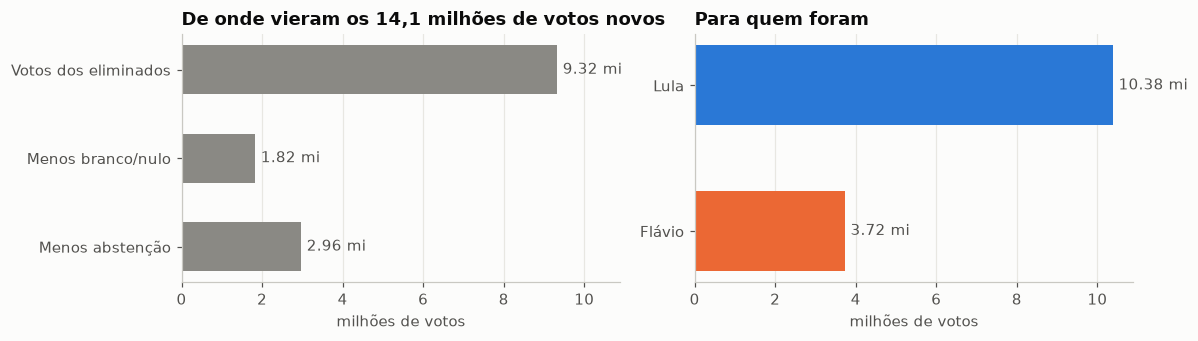

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
a.barh(fontes.index[::-1], fontes.values[::-1] / 1e6, color=CINZA, height=0.55)
a.set_title("De onde vieram os 14,1 milhões de votos novos")
b.barh(ganho.index[::-1], ganho.values[::-1] / 1e6, color=[FLAVIO, LULA], height=0.55)
b.set_title("Para quem foram")
for ax, s in ((a, fontes[::-1]), (b, ganho[::-1])):
    for i, v in enumerate(s.values):
        ax.text(v / 1e6 + 0.15, i, f"{v / 1e6:.2f} mi", va="center", color="#52514e")
    ax.set_xlabel("milhões de votos"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Lula precisava de 2,2 milhões de votos líquidos para empatar. Com 14,1 milhões de votos novos em jogo, bastava ficar com 58% deles; ficou com 74%. A virada, portanto, não depende de uma fonte só: Lula ganhou mais votos que Flávio mesmo se só contarmos os votos dos eliminados (9,3 milhões), e também cresceu a participação.

A pergunta seguinte é onde isso aconteceu.

## 2. Todo estado andou para o mesmo lado

Para comparar turnos com regras diferentes, uso a **disputa direta**: a fatia de Lula entre os votos de Lula + Flávio. No 2º turno ela é a própria votação válida; no 1º, é como estava o mano a mano antes dos eliminados saírem. O *swing* é a diferença entre as duas.

estados com swing positivo para Lula: 28 de 28
swing entre +1.2% (PI) e +4.3% (RJ)


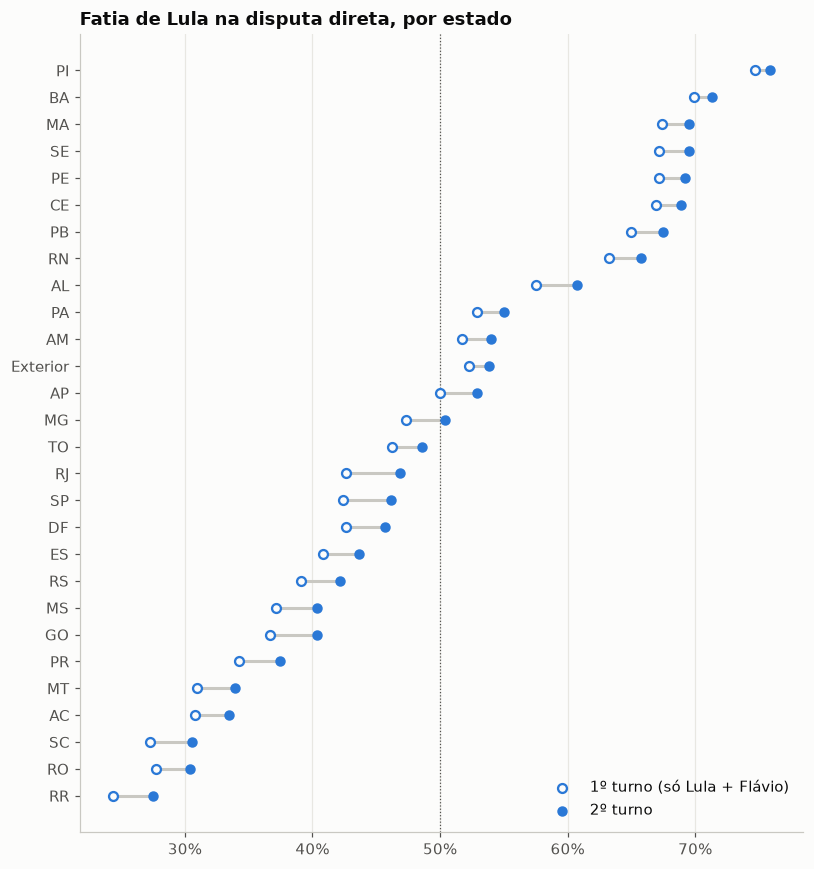

In [5]:
def h2h(df):
    out = pd.DataFrame({
        "h2h_1t": df.lula1 / (df.lula1 + df.flavio1),
        "h2h_2t": df.lula2 / (df.lula2 + df.flavio2),
        "terceiros_1t": df.terceiros / (df.lula1 + df.flavio1 + df.terceiros),
        "comparecimento_1t": 1 - df.abst1 / df.aptos,
        "comparecimento_2t": 1 - df.abst2 / df.aptos2,
    })
    out["swing"] = out.h2h_2t - out.h2h_1t
    return out

uf = m.groupby("uf").sum(numeric_only=True)
uf_h = h2h(uf).sort_values("h2h_2t")
uf_h["regiao"] = uf_h.index.map(REGIAO)
print(f"estados com swing positivo para Lula: {(uf_h.swing > 0).sum()} de {len(uf_h)}")
print(f"swing entre {uf_h.swing.min():+.1%} ({uf_h.swing.idxmin()}) e {uf_h.swing.max():+.1%} ({uf_h.swing.idxmax()})")

fig, ax = plt.subplots(figsize=(7.5, 8))
y = np.arange(len(uf_h))
ax.hlines(y, uf_h.h2h_1t, uf_h.h2h_2t, color="#c9c8c2", lw=2)
ax.scatter(uf_h.h2h_1t, y, s=34, color="#fcfcfb", edgecolor=LULA, lw=1.5, zorder=3, label="1º turno (só Lula + Flávio)")
ax.scatter(uf_h.h2h_2t, y, s=34, color=LULA, zorder=3, label="2º turno")
ax.axvline(0.5, color="#52514e", lw=0.8, ls=":")
ax.set_yticks(y, [u if u != "ZZ" else "Exterior" for u in uf_h.index])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Fatia de Lula na disputa direta, por estado"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

In [6]:
reg = m.groupby("regiao").sum(numeric_only=True)
reg_t = pd.DataFrame({
    "margem_1t": reg.lula1 - reg.flavio1,
    "margem_2t": reg.lula2 - reg.flavio2,
    "terceiros_1t": reg.terceiros,
    "ganho_lula": reg.lula2 - reg.lula1,
    "ganho_flavio": reg.flavio2 - reg.flavio1,
})
reg_t["margem_andou"] = reg_t.margem_2t - reg_t.margem_1t
reg_t["% da virada"] = reg_t.margem_andou / reg_t.margem_andou.sum()
reg_t = reg_t.join(h2h(reg)[["h2h_1t", "h2h_2t", "swing"]]).sort_values("margem_andou", ascending=False)
display(reg_t.style.format({c: "{:,.0f}" for c in reg_t.columns[:6]} | {c: "{:.1%}" for c in reg_t.columns[6:]}))

,margem_1t,margem_2t,terceiros_1t,ganho_lula,ganho_flavio,margem_andou,% da virada,h2h_1t,h2h_2t,swing
regiao,,,,,,,,,,
Sudeste,"-5,662,211","-2,806,770","4,342,954","4,800,333","1,944,892","2,855,441",42.9%,43.6%,47.2%,3.7%
Nordeste,"11,095,611","13,653,696","1,811,095","2,955,848","397,763","2,558,085",38.4%,67.4%,69.4%,2.0%
Sul,"-5,042,624","-4,576,523","1,513,514","1,332,846","866,745","466,101",7.0%,34.2%,37.4%,3.2%
Norte,"-458,835","1,079","631,871","474,024","14,110","459,914",6.9%,47.6%,50.0%,2.4%
Centro-Oeste,"-2,170,393","-1,869,948","987,718","770,876","470,431","300,445",4.5%,36.6%,40.0%,3.4%
Exterior,"13,487","28,657","29,595","42,767","27,597","15,170",0.2%,52.2%,53.9%,1.6%


O swing é maior no Sudeste e no Centro-Oeste, onde os eliminados tinham mais votos, e menor no Nordeste, onde Lula já tinha quase todo o eleitorado disponível. Em votos absolutos, porém, Sudeste e Nordeste fazem juntos a maior parte da virada: o Sudeste porque é grande e andou muito, o Nordeste porque, mesmo com swing pequeno, Lula transformou quase todo voto novo da região em margem.

## 3. Os municípios que viraram

Em quantos municípios o vencedor mudou entre os turnos, e que municípios são esses.

In [7]:
mh = h2h(m).join(m[["uf", "regiao", "municipio", "aptos"]])
mh["venc_1t"] = np.where(m.lula1 > m.flavio1, "Lula", "Flávio")
mh["venc_2t"] = np.where(m.lula2 > m.flavio2, "Lula", "Flávio")
display(pd.crosstab(mh.venc_1t, mh.venc_2t, margins=True).rename_axis(index="1º turno", columns="2º turno"))

viraram = mh[(mh.venc_1t == "Flávio") & (mh.venc_2t == "Lula")]
print(f"\n{len(viraram)} municípios passaram de Flávio para Lula, com {viraram.aptos.sum():,.0f} eleitores")
display(viraram.groupby("uf").agg(municipios=("aptos", "size"), eleitores=("aptos", "sum"))
        .sort_values("municipios", ascending=False).head(10))
print("Maiores municípios que viraram:")
display(viraram.nlargest(12, "aptos")[["municipio", "uf", "aptos", "h2h_1t", "h2h_2t", "terceiros_1t"]])

2º turno,Flávio,Lula,All
1º turno,,,
Flávio,2789,220,3009
Lula,5,2743,2748
All,2794,2963,5757



220 municípios passaram de Flávio para Lula, com 10,948,877 eleitores


,municipios,eleitores
uf,,
MG,76,1838959
SP,33,1715587
PR,20,166085
RS,19,688293
GO,14,150186
TO,12,38788
RJ,9,5170030
AL,7,143583
ZZ,7,46863


Maiores municípios que viraram:


,municipio,uf,aptos,h2h_1t,h2h_2t,terceiros_1t
cd_tse,,,,,,
60011,RIO DE JANEIRO,RJ,4952612,0.478,0.515,0.082
67890,OSASCO,SP,583991,0.488,0.524,0.112
04154,ANANINDEUA,PA,358249,0.493,0.526,0.089
06050,MACAPÁ,AP,321597,0.479,0.510,0.095
71218,SÃO VICENTE,SP,256025,0.457,0.504,0.097
50911,RIBEIRÃO DAS NEVES,MG,218584,0.486,0.523,0.095
63614,COTIA,SP,194159,0.475,0.512,0.120
61638,ARARAQUARA,SP,170310,0.494,0.521,0.093
51551,SANTA LUZIA,MG,164668,0.464,0.507,0.106


In [8]:
# swing por porte do município (eleitores aptos)
faixas = [0, 10_000, 50_000, 200_000, 1_000_000, np.inf]
rotulos = ["até 10 mil", "10–50 mil", "50–200 mil", "200 mil–1 mi", "mais de 1 mi"]
br = m[m.uf != "ZZ"].copy()
br["porte"] = pd.cut(br.aptos, faixas, labels=rotulos)
porte = br.groupby("porte", observed=True).sum(numeric_only=True)
porte_t = h2h(porte)[["h2h_1t", "h2h_2t", "swing", "terceiros_1t", "comparecimento_1t", "comparecimento_2t"]]
porte_t.insert(0, "municipios", br.groupby("porte", observed=True).size())
porte_t["margem_andou"] = (porte.lula2 - porte.flavio2) - (porte.lula1 - porte.flavio1)
display(porte_t.style.format({"municipios": "{:,.0f}", "margem_andou": "{:,.0f}"} |
                             {c: "{:.1%}" for c in porte_t.columns[1:7]}))

,municipios,h2h_1t,h2h_2t,swing,terceiros_1t,comparecimento_1t,comparecimento_2t,margem_andou
porte,,,,,,,,
até 10 mil,"2,941",52.2%,54.1%,1.9%,6.0%,79.3%,80.5%,"504,559"
10–50 mil,"2,134",54.0%,56.2%,2.2%,6.0%,78.9%,80.4%,"1,789,526"
50–200 mil,394,44.4%,47.7%,3.3%,8.0%,79.4%,81.3%,"1,489,300"
200 mil–1 mi,90,44.4%,47.9%,3.5%,9.1%,79.8%,81.7%,"1,444,382"
mais de 1 mi,12,50.3%,53.4%,3.0%,9.9%,78.4%,81.0%,"1,412,219"


## 4. O swing acompanha o voto nos eliminados

Se a virada veio dos eleitores dos candidatos eliminados, o swing deveria ser maior onde eles foram fortes. E se veio da mobilização de abstencionistas, deveria crescer junto com o comparecimento.

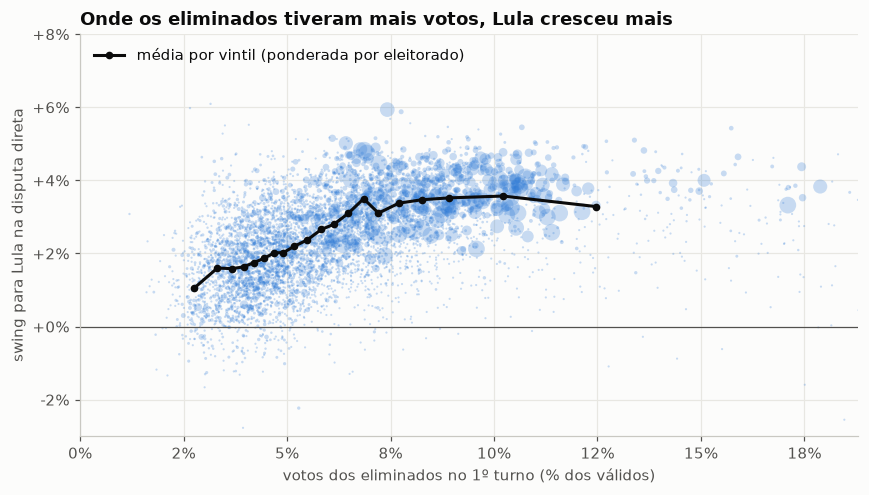

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.6))
d = mh[mh.uf != "ZZ"]
ax.scatter(d.terceiros_1t, d.swing, s=np.clip(d.aptos / 4000, 2, 120), color=LULA, alpha=0.25, lw=0)
bins = pd.qcut(d.terceiros_1t, 20)
g = d.groupby(bins, observed=True).apply(lambda x: pd.Series({
    "x": np.average(x.terceiros_1t, weights=x.aptos), "y": np.average(x.swing, weights=x.aptos)}))
ax.plot(g.x, g.y, color="#0b0b0b", lw=2, marker="o", ms=4, label="média por vintil (ponderada por eleitorado)")
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xlim(0, d.terceiros_1t.quantile(0.995)); ax.set_ylim(-0.03, 0.08)
fmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("votos dos eliminados no 1º turno (% dos válidos)")
ax.set_ylabel("swing para Lula na disputa direta")
ax.set_title("Onde os eliminados tiveram mais votos, Lula cresceu mais"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Para separar os efeitos, uma regressão no nível do município, ponderada pelo eleitorado e com efeito fixo de estado (então a comparação é sempre entre municípios do mesmo estado). A variável dependente é o swing; os regressores são a força de cada eliminado no 1º turno, a variação do comparecimento e a fatia de Lula no 1º turno.

In [10]:
r = (m[m.uf != "ZZ"].assign(
        valid1=lambda x: x.lula1 + x.flavio1 + x.terceiros,
        cury_p=lambda x: x.cury / x.valid1 * 100, renan_p=lambda x: x.renan / x.valid1 * 100,
        caiado_p=lambda x: x.caiado / x.valid1 * 100, outros_p=lambda x: x.outros / x.valid1 * 100,
        d_comp=lambda x: ((x.aptos - x.abst1) - (x.aptos2 - x.abst2)) * -100 / x.aptos)
     .join(mh[["swing", "h2h_1t"]]))
r["swing_pp"] = r.swing * 100
r["lula1t_pp"] = r.h2h_1t * 100
ols = smf.wls("swing_pp ~ cury_p + renan_p + caiado_p + outros_p + d_comp + lula1t_pp + C(uf)",
              data=r, weights=r.aptos).fit(cov_type="cluster", cov_kwds={"groups": r.uf})
coef = ols.summary2().tables[1].loc[["cury_p", "renan_p", "caiado_p", "outros_p", "d_comp", "lula1t_pp"]]
coef.index = ["Cury (p.p. dos válidos)", "Renan Santos", "Caiado", "outros eliminados",
              "variação do comparecimento (p.p.)", "fatia de Lula no 1º turno (p.p.)"]
display(coef[["Coef.", "Std.Err.", "P>|z|", "[0.025", "0.975]"]])
print(f"R² = {ols.rsquared:.2f}, n = {int(ols.nobs):,}; erros agrupados por estado")

/Users/erickpatrickbarcelos/codes/labs/elections/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 32, but rank is 6
  res = self.wald_test(


,Coef.,Std.Err.,P>|z|,[0.025,0.975]
Cury (p.p. dos válidos),0.291,0.036,0.000,0.220,0.362
Renan Santos,0.080,0.065,0.221,-0.048,0.208
Caiado,0.028,0.058,0.630,-0.085,0.141
outros eliminados,-0.027,0.259,0.917,-0.534,0.480
variação do comparecimento (p.p.),0.014,0.030,0.627,-0.044,0.072
fatia de Lula no 1º turno (p.p.),-0.049,0.004,0.000,-0.058,-0.040


R² = 0.70, n = 5,571; erros agrupados por estado


Leitura: o swing de um município depende de *como* os votos dos eliminados se dividiram em relação ao mano a mano local. Se o eleitor de um candidato se dividisse exatamente como o resto do município, o coeficiente seria zero. Um coeficiente positivo quer dizer que esse eleitor foi mais para Lula do que o município já ia. Com a fatia média de Lula na disputa direta perto de 45%, o coeficiente de 0,29 para Cury sugere que algo como três quartos do eleitor do Cury que escolheu um finalista escolheu Lula. Renan Santos e Caiado ficam perto de zero: seus eleitores se dividiram mais ou menos como os municípios onde moram. A variação do comparecimento, controlando o resto, não explica o swing.

O coeficiente negativo da fatia de Lula no 1º turno é o padrão esperado de teto: onde Lula já tinha quase tudo, sobrava pouco para crescer.

## 5. Uma conta que não depende de modelo

Antes de estimar fluxos, um limite contábil. Ele precisa de uma hipótese, que deixo explícita: **os fluxos líquidos são os fluxos reais.** Quer dizer, quem votou em Lula ou Flávio no 1º turno repetiu o voto (a seção 6 confirma que isso é quase exato), e não houve troca de lugar entre grupos, como eleitores dos eliminados indo para o branco/nulo enquanto quem votou branco/nulo vai para um finalista. Sob essa hipótese, a margem andou 6,66 milhões e só pode ter vindo de três fontes: os 9,32 milhões de votos dos eliminados, a queda líquida de 1,82 milhão em branco/nulo e a queda líquida de 2,96 milhões na abstenção.

In [11]:
andou = (tot.lula2 - tot.flavio2) - (tot.lula1 - tot.flavio1)
novos = (tot.bn1 - tot.bn2) + (tot.abst1 - tot.abst2)
minimo_terceiros = andou - novos
print(f"margem que andou: {andou:,.0f}")
print(f"teto da contribuição de branco/nulo + abstenção (se 100% fosse para Lula): {novos:,.0f}")
print(f"→ os eliminados deram a Lula pelo menos {minimo_terceiros:,.0f} de margem líquida")
print(f"→ entre os eleitores dos eliminados que escolheram um finalista, Lula teve no mínimo "
      f"{(1 + minimo_terceiros / tot.terceiros) / 2:.0%}")
print(f"\nno sentido oposto, mesmo que 100% dos eliminados tivessem ido para Lula ({tot.terceiros:,.0f}), "
      f"os votos novos teriam que ter dado ao menos {andou - tot.terceiros:,.0f} de margem,")
print(f"ou seja, Lula precisou de pelo menos {(1 + (andou - tot.terceiros) / novos) / 2:.0%} do saldo de novos votantes")

margem que andou: 6,655,156
teto da contribuição de branco/nulo + abstenção (se 100% fosse para Lula): 4,781,485
→ os eliminados deram a Lula pelo menos 1,873,671 de margem líquida
→ entre os eleitores dos eliminados que escolheram um finalista, Lula teve no mínimo 60%

no sentido oposto, mesmo que 100% dos eliminados tivessem ido para Lula (9,316,747), os votos novos teriam que ter dado ao menos -2,661,591 de margem,
ou seja, Lula precisou de pelo menos 22% do saldo de novos votantes


Sob essa hipótese, **a virada não fecha sem que os eleitores dos eliminados tenham pendido para Lula**: mesmo no cenário extremo em que todo eleitor que saiu do branco/nulo ou da abstenção foi para Lula, os eliminados ainda precisam ter se dividido pelo menos 60/40 a favor dele. O limite não usa nenhum modelo estatístico, mas depende inteiramente da hipótese de não troca, e a checagem de robustez da seção 6 mostra que ela não é garantida.

## 6. Estimativa ecológica: para onde foi cada grupo

Para ir além do limite, estimo os fluxos por regressão ecológica. A especificação principal trabalha com **fluxos líquidos**, que é o que a identidade contábil da seção 1 permite medir sem ambiguidade. Em cada município $i$, o ganho de Lula entre turnos é modelado como uma fração de cada fonte de votos novos:

$$
\Delta \text{Lula}_i = \sum_k a_k\, S_{i,k} + \varepsilon_i, \qquad 0 \le a_k \le 1,
$$

com as fontes $S_k$ = votos de Cury, Renan Santos, Caiado, outros eliminados, queda de branco/nulo e queda de abstenção (todas em fração do eleitorado). Como $\Delta \text{Lula}_i + \Delta \text{Flávio}_i = \sum_k S_{i,k}$ por construção, $a_k$ é a fatia da fonte $k$ que ficou com Lula e $1 - a_k$ a que ficou com Flávio. Os votos de um eliminado que foram para branco/nulo aparecem como uma queda menor de branco/nulo; por isso $a_k$ lê-se como "divisão entre os finalistas".

A hipótese forte é que $a_k$ é o mesmo em todos os municípios do grupo. Estimo por região, agrego para o país pesando pelo tamanho de cada fonte, e uso bootstrap de municípios dentro de cada região para a incerteza. O exterior fica fora (0,2% da virada e sem estrutura municipal comparável).

In [12]:
FONTES = ["cury", "renan", "caiado", "outros", "menos_bn", "menos_abst"]
NOME_F = ["Cury", "Renan Santos", "Caiado", "outros eliminados", "queda de branco/nulo", "queda de abstenção"]

dom = m[m.uf != "ZZ"].assign(menos_bn=lambda x: x.bn1 - x.bn2, menos_abst=lambda x: x.abst1 - x.abst2,
                             d_lula=lambda x: x.lula2 - x.lula1)
residuo = (dom.d_lula + dom.flavio2 - dom.flavio1) - dom[FONTES].sum(axis=1)
print(f"identidade fecha município a município: resíduo máximo de {residuo.abs().max():,.0f} votos (trânsito)")

def fluxo(df):
    A = df[FONTES].to_numpy(float) / df.aptos.to_numpy(float)[:, None]
    b = df.d_lula.to_numpy(float) / df.aptos.to_numpy(float)
    w = np.sqrt(df.aptos.to_numpy(float))
    return lsq_linear(A * w[:, None], b * w, bounds=(0, 1)).x

def margem_por_fonte(df):
    # contribuição líquida de cada fonte para a margem: (2a - 1) x votos, região por região
    return sum((2 * fluxo(x) - 1) * x[FONTES].sum().to_numpy() for _, x in df.groupby("regiao"))

a_reg = pd.DataFrame({g: fluxo(x) for g, x in dom.groupby("regiao")}, index=NOME_F).T
peso = dom.groupby("regiao")[FONTES].sum().set_axis(NOME_F, axis=1)
a_nac = (a_reg * peso).sum() / peso.sum()

rng = np.random.default_rng(2026)
boot_a, boot_c = [], []
for _ in range(300):
    s = pd.concat([x.sample(len(x), replace=True, random_state=rng) for _, x in dom.groupby("regiao")])
    ar = pd.DataFrame({g: fluxo(x) for g, x in s.groupby("regiao")}, index=NOME_F).T
    pw = s.groupby("regiao")[FONTES].sum().set_axis(NOME_F, axis=1)
    boot_a.append(((ar * pw).sum() / pw.sum()).to_numpy())
    boot_c.append(margem_por_fonte(s) * dom[FONTES].sum().sum() / s[FONTES].sum().sum())
boot_a, boot_c = np.array(boot_a), np.array(boot_c)

tab = pd.DataFrame({"fatia para Lula": a_nac,
                    "IC 2,5%": np.percentile(boot_a, 2.5, axis=0), "IC 97,5%": np.percentile(boot_a, 97.5, axis=0)})
display(tab.style.format("{:.0%}"))
print("Por região (fatia para Lula):")
display(a_reg.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1, axis=None))

identidade fecha município a município: resíduo máximo de 845 votos (trânsito)


,fatia para Lula,"IC 2,5%","IC 97,5%"
Cury,82%,74%,94%
Renan Santos,63%,56%,73%
Caiado,75%,60%,81%
outros eliminados,43%,24%,62%
queda de branco/nulo,98%,97%,99%
queda de abstenção,60%,55%,66%


Por região (fatia para Lula):


,Cury,Renan Santos,Caiado,outros eliminados,queda de branco/nulo,queda de abstenção
Centro-Oeste,73%,85%,50%,100%,100%,53%
Nordeste,100%,89%,86%,0%,100%,71%
Norte,93%,74%,82%,0%,69%,47%
Sudeste,79%,55%,100%,44%,100%,49%
Sul,65%,47%,35%,64%,100%,76%


,margem para Lula,"IC 2,5%","IC 97,5%"
Cury,"2,234,512","1,624,778","3,082,416"
Renan Santos,"707,466","330,014","1,185,818"
Caiado,"1,296,457","542,992","1,527,260"
outros eliminados,"-82,314","-306,030","141,180"
queda de branco/nulo,"1,761,554","1,646,878","1,874,374"
queda de abstenção,"597,990","260,781","964,201"


soma das contribuições: 6,515,665; margem que de fato andou (sem exterior): 6,639,986
  eliminados: 4,156,121 (63%)
  novos votantes (branco/nulo + abstenção): 2,359,544 (36%)


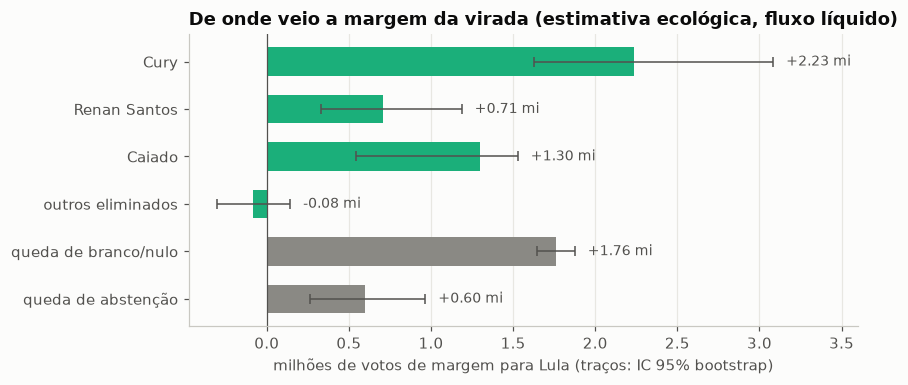

In [13]:
contrib = pd.DataFrame({"margem para Lula": margem_por_fonte(dom),
                        "IC 2,5%": np.percentile(boot_c, 2.5, axis=0),
                        "IC 97,5%": np.percentile(boot_c, 97.5, axis=0)}, index=NOME_F)
display(contrib.style.format("{:,.0f}"))
obs_andou = (dom.lula2 - dom.flavio2).sum() - (dom.lula1 - dom.flavio1).sum()
print(f"soma das contribuições: {contrib.iloc[:, 0].sum():,.0f}; margem que de fato andou (sem exterior): {obs_andou:,.0f}")
grupos = {"eliminados": NOME_F[:4], "novos votantes (branco/nulo + abstenção)": NOME_F[4:]}
for g, idx in grupos.items():
    print(f"  {g}: {contrib.loc[idx].iloc[:, 0].sum():,.0f} ({contrib.loc[idx].iloc[:, 0].sum() / obs_andou:.0%})")

s = contrib.iloc[:, 0].iloc[::-1]
err = np.abs(contrib[["IC 2,5%", "IC 97,5%"]].iloc[::-1].to_numpy().T - s.to_numpy())
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(s.index, s / 1e6, xerr=err / 1e6, color=[CINZA] * 2 + [TERCEIROS] * 4, height=0.6,
        error_kw=dict(ecolor="#52514e", lw=1, capsize=3))
ax.axvline(0, color="#52514e", lw=0.8)
topo = contrib["IC 97,5%"].iloc[::-1].to_numpy()
for i, v in enumerate(s):
    ax.text(max(topo[i], 0) / 1e6 + 0.08, i, f"{v / 1e6:+.2f} mi", va="center", color="#52514e", fontsize=9)
ax.set_xlabel("milhões de votos de margem para Lula (traços: IC 95% bootstrap)"); ax.grid(axis="y", visible=False)
ax.set_xlim(right=3.6)
ax.set_title("De onde veio a margem da virada (estimativa ecológica, fluxo líquido)")
plt.tight_layout(); plt.show()

In [14]:
# validação: quanto do swing municipal o modelo explica
pred = pd.concat([pd.Series(x[FONTES].to_numpy() @ fluxo(x), index=x.index) for _, x in dom.groupby("regiao")])
l2_pred = dom.lula1 + pred.loc[dom.index]
f2_pred = dom.flavio1 + dom[FONTES].sum(axis=1) - pred.loc[dom.index]
sw_pred = l2_pred / (l2_pred + f2_pred) - mh.loc[dom.index, "h2h_1t"]
print(f"correlação entre swing previsto e observado: {np.corrcoef(sw_pred, mh.loc[dom.index, 'swing'])[0, 1]:.2f}")
print(f"erro absoluto mediano na fatia de Lula no 2º turno: "
      f"{(l2_pred / (l2_pred + f2_pred) - mh.loc[dom.index, 'h2h_2t']).abs().median():.1%}")

correlação entre swing previsto e observado: 0.68
erro absoluto mediano na fatia de Lula no 2º turno: 0.7%


### Checagem de robustez: a matriz de transferência completa

A especificação líquida não diz nada sobre fluxos brutos (por exemplo, eleitor do Lula que se absteve no 2º turno, compensado por um abstencionista que foi votar). A alternativa clássica é uma **matriz de transferência**: o resultado do 2º turno (Lula, Flávio, branco/nulo, abstenção) como combinação do resultado do 1º,

$$
y_{i,d}^{(2)} = \sum_o x_{i,o}^{(1)}\, \beta_{o \to d}, \qquad \beta_{o \to d} \ge 0, \qquad \sum_d \beta_{o \to d} = 1,
$$

com origens Lula, Flávio, Cury, Renan Santos, Caiado, outros, branco/nulo e abstenção, também estimada por região.

In [15]:
ORIG = ["lula1", "flavio1", "cury", "renan", "caiado", "outros", "bn1", "abst1"]
DEST = ["lula2", "flavio2", "bn2", "abst2"]
NOME_O = ["Lula", "Flávio", "Cury", "Renan Santos", "Caiado", "outros", "branco/nulo", "abstenção"]
NOME_D = ["→ Lula", "→ Flávio", "→ branco/nulo", "→ abstenção"]

def transferencia(df):
    X = df[ORIG].to_numpy(float) / df.aptos.to_numpy(float)[:, None]
    Y = df[DEST].to_numpy(float) / df.aptos.to_numpy(float)[:, None]
    w = df.aptos.to_numpy(float) / df.aptos.sum()
    k, j = len(ORIG), len(DEST)

    def f(b):
        R = X @ b.reshape(k, j) - Y
        return (w[:, None] * R ** 2).sum(), (2 * X.T @ (w[:, None] * R)).ravel()

    cons = [{"type": "eq", "fun": (lambda b, o=o: b.reshape(k, j)[o].sum() - 1)} for o in range(k)]
    res = minimize(f, np.full(k * j, 1 / j), jac=True, bounds=[(0, 1)] * (k * j), constraints=cons,
                   method="SLSQP", options={"maxiter": 500, "ftol": 1e-12})
    assert res.success, res.message
    return res.x.reshape(k, j)

B_reg = {g: transferencia(x) for g, x in dom.groupby("regiao")}
peso_o = dom.groupby("regiao")[ORIG].sum()
B_nac = sum(B_reg[g] * peso_o.loc[g].to_numpy()[:, None] for g in B_reg) / peso_o.sum().to_numpy()[:, None]
display(pd.DataFrame(B_nac, index=NOME_O, columns=NOME_D).style.format("{:.0%}")
        .background_gradient(cmap="Blues", vmin=0, vmax=1, axis=None))

c = sum((B[:, 0] - B[:, 1]) * dom[dom.regiao == g][ORIG].sum().to_numpy() for g, B in B_reg.items())
c[0] -= dom.lula1.sum(); c[1] += dom.flavio1.sum()
comp = pd.DataFrame({"matriz completa": c}, index=NOME_O)
comp["eliminados / novos votantes"] = comp.index.map(
    lambda o: "eliminados" if o in ("Cury", "Renan Santos", "Caiado", "outros") else
              "novos votantes" if o in ("branco/nulo", "abstenção") else "finalistas")
display(comp.groupby("eliminados / novos votantes").sum().join(
    pd.Series({"eliminados": contrib.iloc[:4, 0].sum(), "novos votantes": contrib.iloc[4:, 0].sum(),
               "finalistas": 0}, name="fluxo líquido")).style.format("{:,.0f}"))

,→ Lula,→ Flávio,→ branco/nulo,→ abstenção
Lula,99%,0%,0%,0%
Flávio,0%,100%,0%,0%
Cury,47%,33%,20%,0%
Renan Santos,46%,41%,11%,1%
Caiado,45%,42%,12%,2%
outros,53%,44%,3%,0%
branco/nulo,70%,0%,30%,0%
abstenção,7%,1%,2%,90%


,matriz completa,fluxo líquido
eliminados / novos votantes,,
eliminados,"775,088","4,156,121"
finalistas,"-219,036",0
novos votantes,"6,089,767","2,359,544"


As duas especificações concordam em parte e discordam em parte, e a discordância é informativa.

**Onde concordam:** eleitores de Lula e de Flávio no 1º turno ficaram com o mesmo candidato (lealdade de 99–100%); a maior parte de quem se absteve no 1º turno se absteve de novo; e tanto os eliminados quanto os novos votantes, somados, pesaram para Lula em todas as regiões.

**Onde discordam:** a divisão do crédito entre eliminados e branco/nulo. A matriz completa atribui ao eleitor que votou branco ou nulo no 1º turno uma migração forte para Lula, e manda parte do eleitor do Cury para o branco/nulo. As duas histórias produzem os mesmos totais municipais, porque branco/nulo e voto nos eliminados estão correlacionados geograficamente com a força de Lula. Com dados agregados por município, essa troca não é identificável. A matriz completa conta exatamente a história de troca que a seção 5 tinha excluído por hipótese, e por isso fica abaixo daquele limite. Qual das duas está mais perto da realidade não dá para decidir com este dado: as duas são plausíveis (eleitor de *outsider* anulando no 2º turno é comum; voto nulo por erro no 1º turno, com seis cargos na urna, também). O que dá para afirmar é o intervalo: **os eliminados responderam por algo entre 0,8 e 4,2 milhões dos 6,6 milhões de margem**, e os novos votantes (quem saiu do branco/nulo e da abstenção) pelo resto. Separar de vez exigiria dado de painel ou pesquisa com recordação de voto.

## Conclusões

1. **A conta é simples e larga.** Lula precisava tirar 2,2 milhões de votos de diferença. Entraram 14,1 milhões de votos novos para os finalistas (9,3 mi dos eliminados, 3,0 mi de queda na abstenção, 1,8 mi de queda em branco/nulo), e Lula ficou com 74% deles. A margem andou 6,7 milhões.
2. **Não foi um movimento localizado.** Os 27 estados e o exterior andaram na direção de Lula na disputa direta, entre +1,2 ponto (PI) e +4,3 pontos (RJ). Sudeste (43%) e Nordeste (38%) fizeram quatro quintos da virada: o primeiro porque andou muito, o segundo porque converteu quase todo voto novo em margem.
3. **O swing foi maior onde havia mais voto para redistribuir.** Ele cresce com a força dos eliminados no município, é maior nas cidades médias e grandes do que nas pequenas, e 220 municípios trocaram de vencedor (contra 5 no sentido oposto), entre eles a cidade do Rio de Janeiro, Osasco, Ananindeua e Macapá.
4. **O eleitor do Cury é o sinal mais claro.** Em todas as especificações ele pende para Lula: regressão com efeito fixo de estado, fluxo líquido (82%) e matriz completa (59% entre os que escolheram um finalista). Renan Santos e Caiado se dividiram de forma mais equilibrada, com diferença grande por região (no Sul, pendendo para Flávio).
5. **Quem votou em um finalista no 1º turno repetiu o voto.** A lealdade estimada é de 99–100% nos dois lados. A virada veio da redistribuição, não de troca de lado.
6. **O que não dá para separar:** quanto da margem veio dos eliminados e quanto de quem voltou a votar ou deixou de anular. Com dados agregados por município, as estimativas vão de 0,8 a 4,2 milhões para os eliminados, dependendo da hipótese sobre fluxos cruzados.

## Limites

- **Falácia ecológica.** Tudo aqui é inferido de totais municipais. A matriz de transferência é a melhor explicação linear de como os municípios se moveram, não um registro do que cada eleitor fez. Ela pode errar de forma sistemática se, dentro do mesmo município, o eleitor do Cury que foi votar no 2º turno for diferente do que ficou em casa.
- **Taxas constantes dentro da região.** O modelo supõe que o eleitor de um candidato se comporta igual em todos os municípios da região. Estimar por região ameniza, não resolve.
- **Abstenção é um fluxo nos dois sentidos.** O saldo de comparecimento subiu 3 milhões, mas por baixo disso há gente que votou no 1º turno e não no 2º e vice-versa. A matriz captura parte disso (a linha "abstenção" e as colunas "→ abstenção"), mas é a parte menos identificada do modelo.
- **Exterior fora do modelo.** As 200 e poucas cidades no exterior entram nas contas descritivas, mas não na matriz.
- **Sem dados de perfil.** Este notebook usa só resultado eleitoral. Cruzar com renda, escolaridade e religião (Censo 2022) é o próximo passo natural e fica para o experimento `elections/`.